<a href="https://colab.research.google.com/github/SharikaTasnim23/Bd_Flood_-_Flash_Flood/blob/main/Flood_Prototype.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install requests pandas numpy matplotlib urllib3


In [2]:
"""Bangladesh flood/flash-flood precursor monitoring prototype.

This project combines historical weather features, short-range precipitation forecasts,
and optional modelled GloFAS river-discharge forecasts. The rule-based index is exploratory;
this is NOT a trained or validated flood-forecasting model and must not issue warnings.
"""
from __future__ import annotations

import re
import time
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
FORECAST_URL = "https://api.open-meteo.com/v1/forecast"
FLOOD_URL = "https://flood-api.open-meteo.com/v1/flood"
ELEVATION_URL = "https://api.opentopodata.org/v1/srtm30m"
CACHE_DIR = Path("data_cache")
OUTPUT_DIR = Path("outputs")

# Representative river-corridor points for an exploratory prototype; NOT official gauge sites.
STATIONS = [
    {"station": "Brahmaputra_Rangpur", "river": "Brahmaputra", "lat": 25.807, "lon": 89.636},
    {"station": "Brahmaputra_Gaibandha", "river": "Brahmaputra", "lat": 25.328, "lon": 89.528},
    {"station": "Jamuna_Sirajganj", "river": "Jamuna", "lat": 24.937, "lon": 89.937},
    {"station": "Surma_Sylhet", "river": "Surma", "lat": 25.069, "lon": 91.399},
    {"station": "Padma_Rajshahi", "river": "Padma", "lat": 24.363, "lon": 88.601},
    {"station": "Meghna_LowerBasin", "river": "Meghna", "lat": 23.200, "lon": 90.700},
]

# Approximate regional weather-grid context points in the northeastern hill region.
# These are not rain gauges, and their hydrological connection to individual Bangladesh
# stations has NOT yet been delineated. Use as exploratory context only until catchments
# and upstream-downstream relationships are verified with a DEM/hydrography dataset.
UPSTREAM_RAINFALL_CONTEXT = [
    {"station": "Meghalaya_Cherrapunji_context", "river": "Meghalaya regional rainfall context", "lat": 25.2700, "lon": 91.7320},
    {"station": "Meghalaya_Shillong_context", "river": "Meghalaya regional rainfall context", "lat": 25.5788, "lon": 91.8933},
    {"station": "Tripura_Agartala_context", "river": "Tripura regional rainfall context", "lat": 23.8315, "lon": 91.2868},
]
WEATHER_FORECAST_POINTS = STATIONS + UPSTREAM_RAINFALL_CONTEXT


def make_session() -> requests.Session:
    """Create a session with retries for transient API/rate-limit failures."""
    session = requests.Session()
    retry = Retry(
        total=4,
        connect=4,
        read=4,
        backoff_factor=1.5,
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=frozenset(["GET"]),
        respect_retry_after_header=True,
    )
    adapter = HTTPAdapter(max_retries=retry)
    session.mount("https://", adapter)
    session.headers.update({"User-Agent": "BangladeshFloodExposurePrototype/0.1 (educational project)"})
    return session


SESSION = make_session()


def _safe_name(value: str) -> str:
    return re.sub(r"[^A-Za-z0-9_-]+", "_", value).strip("_")


In [3]:
def fetch_weather(
    station: dict,
    start_date: str,
    end_date: str,
    cache_dir: Path = CACHE_DIR,
    session: requests.Session = SESSION,
) -> pd.DataFrame:
    """Fetch daily reanalysis weather from Open-Meteo Archive with local caching."""
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_path = cache_dir / f"weather_{_safe_name(station['station'])}_{start_date}_{end_date}.csv"
    if cache_path.exists():
        cached = pd.read_csv(cache_path, parse_dates=["date"])
        cached["station"] = station["station"]
        cached["river"] = station["river"]
        return cached

    params = {
        "latitude": station["lat"],
        "longitude": station["lon"],
        "start_date": start_date,
        "end_date": end_date,
        "daily": "precipitation_sum,temperature_2m_max,temperature_2m_min",
        "timezone": "Asia/Dhaka",
        "models": "era5",
    }
    response = session.get(ARCHIVE_URL, params=params, timeout=45)
    response.raise_for_status()
    daily = response.json().get("daily", {})
    required = ("time", "precipitation_sum")
    if any(key not in daily for key in required):
        raise ValueError(f"Weather API returned incomplete daily data for {station['station']}.")

    frame = pd.DataFrame({
        "date": pd.to_datetime(daily["time"]),
        "rainfall_mm": daily["precipitation_sum"],
        "temp_max_c": daily.get("temperature_2m_max"),
        "temp_min_c": daily.get("temperature_2m_min"),
    })
    frame["station"] = station["station"]
    frame["river"] = station["river"]
    frame.to_csv(cache_path, index=False)
    return frame


def fetch_elevations(
    stations: list[dict],
    session: requests.Session = SESSION,
) -> dict[str, Optional[float]]:
    """Fetch SRTM-derived terrain elevation for the sampled coordinates."""
    locations = "|".join(f"{s['lat']},{s['lon']}" for s in stations)
    response = session.get(ELEVATION_URL, params={"locations": locations}, timeout=30)
    response.raise_for_status()
    results = response.json().get("results", [])
    if len(results) != len(stations):
        raise ValueError("Elevation API response count did not match input locations.")
    return {
        station["station"]: result.get("elevation")
        for station, result in zip(stations, results)
    }



def fetch_hourly_rainfall_forecast(
    station: dict,
    session: requests.Session = SESSION,
) -> tuple[pd.DataFrame, dict]:
    """Fetch forecast precipitation and summarize upcoming 6 h, 24 h and 72 h.

    This is a weather-forecast signal, NOT a flood forecast. Forecast data can be
    unavailable or revised; all outputs should be timestamped and checked.
    """
    params = {
        "latitude": station["lat"],
        "longitude": station["lon"],
        "hourly": "precipitation,precipitation_probability",
        "forecast_days": 7,
        "timezone": "Asia/Dhaka",
    }
    response = session.get(FORECAST_URL, params=params, timeout=25)
    response.raise_for_status()
    hourly = response.json().get("hourly", {})
    if "time" not in hourly or "precipitation" not in hourly:
        raise ValueError(f"Incomplete hourly forecast for {station['station']}.")

    frame = pd.DataFrame({
        "forecast_time_local": pd.to_datetime(hourly["time"]),
        "forecast_precip_mm": pd.to_numeric(hourly["precipitation"], errors="coerce"),
        "precip_probability_pct": pd.to_numeric(
            hourly.get("precipitation_probability", [np.nan] * len(hourly["time"])),
            errors="coerce",
        ),
    })
    now_local = pd.Timestamp.now(tz="Asia/Dhaka").tz_localize(None)
    frame = frame.loc[frame["forecast_time_local"] >= now_local.floor("h")].copy()
    if frame.empty:
        raise ValueError(f"No future forecast timestamps returned for {station['station']}.")

    def next_hours(hours: int) -> pd.DataFrame:
        # One row per hour; explicitly cap to the requested lead-time window.
        return frame.head(hours)

    next6 = next_hours(6)
    next24 = next_hours(24)
    next72 = next_hours(72)
    summary = {
        "station": station["station"],
        "river_or_area": station["river"],
        "latitude": station["lat"],
        "longitude": station["lon"],
        "forecast_fetched_at_local": pd.Timestamp.now(tz="Asia/Dhaka").isoformat(),
        "forecast_start_local": frame["forecast_time_local"].iloc[0],
        "rain_forecast_next_6h_mm": float(next6["forecast_precip_mm"].sum(min_count=1)),
        "rain_forecast_next_24h_mm": float(next24["forecast_precip_mm"].sum(min_count=1)),
        "rain_forecast_next_72h_mm": float(next72["forecast_precip_mm"].sum(min_count=1)),
        "max_hourly_rain_next_24h_mm": float(next24["forecast_precip_mm"].max()),
        "max_precip_probability_next_24h_pct": (
            float(next24["precip_probability_pct"].max())
            if next24["precip_probability_pct"].notna().any() else np.nan
        ),
    }
    frame["station"] = station["station"]
    frame["river_or_area"] = station["river"]
    frame["forecast_fetched_at_local"] = summary["forecast_fetched_at_local"]
    return frame, summary


def fetch_glofas_discharge_forecast(
    station: dict,
    session: requests.Session = SESSION,
) -> pd.DataFrame:
    """Fetch modelled daily GloFAS river-discharge forecasts for coordinate context.

    The closest 5-km grid river may not be the named/nearest river. These values
    are model outputs, not observed gauge readings and must not be used as labels.
    """
    params = {
        "latitude": station["lat"],
        "longitude": station["lon"],
        "daily": "river_discharge,river_discharge_p25,river_discharge_p75",
        "forecast_days": 7,
        "timezone": "Asia/Dhaka",
    }
    response = session.get(FLOOD_URL, params=params, timeout=25)
    response.raise_for_status()
    daily = response.json().get("daily", {})
    if "time" not in daily or "river_discharge" not in daily:
        raise ValueError(f"Incomplete GloFAS discharge forecast for {station['station']}.")
    out = pd.DataFrame({
        "date": pd.to_datetime(daily["time"]),
        "river_discharge_m3s_modelled": pd.to_numeric(daily["river_discharge"], errors="coerce"),
        "discharge_p25_m3s_modelled": pd.to_numeric(
            daily.get("river_discharge_p25", [np.nan] * len(daily["time"])), errors="coerce"
        ),
        "discharge_p75_m3s_modelled": pd.to_numeric(
            daily.get("river_discharge_p75", [np.nan] * len(daily["time"])), errors="coerce"
        ),
    })
    out["station"] = station["station"]
    out["river_or_area"] = station["river"]
    out["requested_latitude"] = station["lat"]
    out["requested_longitude"] = station["lon"]
    out["model_grid_latitude"] = response.json().get("latitude")
    out["model_grid_longitude"] = response.json().get("longitude")
    out["forecast_fetched_at_local"] = pd.Timestamp.now(tz="Asia/Dhaka").isoformat()
    return out


In [4]:
def engineer_features(frame: pd.DataFrame, api_decay: float = 0.85) -> pd.DataFrame:
    """Create lagged rainfall indicators; no synthetic water levels/labels are created."""
    if "rainfall_mm" not in frame:
        raise ValueError("frame must contain rainfall_mm")
    out = frame.sort_values(["station", "date"]).copy()
    out["rainfall_mm"] = pd.to_numeric(out["rainfall_mm"], errors="coerce").clip(lower=0)
    out["rain_3d_sum_mm"] = out.groupby("station")["rainfall_mm"].transform(
        lambda s: s.rolling(3, min_periods=1).sum()
    )
    out["rain_7d_sum_mm"] = out.groupby("station")["rainfall_mm"].transform(
        lambda s: s.rolling(7, min_periods=1).sum()
    )

    def calc_api(values: pd.Series) -> pd.Series:
        result = np.zeros(len(values), dtype=float)
        for i, val in enumerate(values.fillna(0).to_numpy(dtype=float)):
            result[i] = val + (api_decay * result[i - 1] if i > 0 else 0.0)
        return pd.Series(result, index=values.index)

    out["antecedent_precip_idx"] = out.groupby("station", group_keys=False)["rainfall_mm"].apply(calc_api)
    out["month"] = out["date"].dt.month
    out["month_sin"] = np.sin(2 * np.pi * out["month"] / 12.0)
    out["month_cos"] = np.cos(2 * np.pi * out["month"] / 12.0)
    return out


def _empirical_percentile(history: pd.Series, current: float) -> float:
    """Return the fraction of available historical values less than/equal to current."""
    valid = pd.to_numeric(history, errors="coerce").dropna()
    if valid.empty or not np.isfinite(current):
        return np.nan
    return float((valid <= current).mean())


def create_latest_screening_summary(
    features: pd.DataFrame,
    stations: list[dict],
    elevations: dict[str, Optional[float]],
) -> pd.DataFrame:
    """Create an exploratory relative exposure index; it is not a flood probability."""
    rows = []
    for station in stations:
        group = features.loc[features["station"] == station["station"]].sort_values("date")
        group = group.dropna(subset=["rainfall_mm"])
        if group.empty:
            continue
        latest = group.iloc[-1]
        # Relative scores compare the latest observation with this point's downloaded history.
        rain7_pct = _empirical_percentile(group["rain_7d_sum_mm"], float(latest["rain_7d_sum_mm"]))
        api_pct = _empirical_percentile(group["antecedent_precip_idx"], float(latest["antecedent_precip_idx"]))
        elevation = elevations.get(station["station"])
        low_elevation_indicator = (
            float(np.exp(-max(float(elevation), 0.0) / 20.0))
            if elevation is not None and np.isfinite(float(elevation)) else np.nan
        )

        # Weighted mean is re-normalized if the elevation service did not return a value.
        components = [(rain7_pct, 0.55), (api_pct, 0.30), (low_elevation_indicator, 0.15)]
        available = [(v, w) for v, w in components if pd.notna(v)]
        score = 100.0 * sum(v * w for v, w in available) / sum(w for _, w in available)
        rows.append({
            "station": station["station"],
            "river": station["river"],
            "latitude": station["lat"],
            "longitude": station["lon"],
            "latest_data_date": latest["date"],
            "elevation_m_srtm": elevation,
            "rainfall_latest_mm": latest["rainfall_mm"],
            "rain_7d_sum_mm": latest["rain_7d_sum_mm"],
            "rain_7d_historical_percentile": rain7_pct,
            "api_historical_percentile": api_pct,
            "low_elevation_indicator": low_elevation_indicator,
            "exploratory_exposure_index_0_100": score,
        })
    return pd.DataFrame(rows).sort_values("exploratory_exposure_index_0_100", ascending=False)


In [5]:
def run(
    start_date: str = "2018-01-01",
    end_date: Optional[str] = None,
    include_live_forecasts: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Download/cache historical data; optionally add live weather/GloFAS forecast context."""
    if end_date is None:
        # Exclude the most recent days because archive products may not yet be complete.
        end_date = (pd.Timestamp.now(tz="Asia/Dhaka").normalize() - pd.Timedelta(days=7)).date().isoformat()
    if pd.Timestamp(start_date) > pd.Timestamp(end_date):
        raise ValueError("start_date must not be after end_date")

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    frames = []
    errors = []
    for i, station in enumerate(STATIONS):
        try:
            print(f"Fetching weather {i + 1}/{len(STATIONS)}: {station['station']}")
            frames.append(fetch_weather(station, start_date, end_date))
        except (requests.RequestException, ValueError, KeyError) as exc:
            errors.append(f"{station['station']}: {exc}")
            print(f"  Skipped: {exc}")
        time.sleep(0.4)

    if not frames:
        raise RuntimeError("No weather data was downloaded. Check network/API availability and try again.")
    raw = pd.concat(frames, ignore_index=True)
    raw["date"] = pd.to_datetime(raw["date"])
    features = engineer_features(raw)
    try:
        elevations = fetch_elevations(STATIONS)
    except (requests.RequestException, ValueError, KeyError) as exc:
        print(f"Elevation lookup unavailable; continuing without elevation: {exc}")
        elevations = {s["station"]: None for s in STATIONS}

    for station in STATIONS:
        features.loc[features["station"] == station["station"], "elevation_m_srtm"] = elevations.get(station["station"])

    summary = create_latest_screening_summary(features, STATIONS, elevations)
    features.to_csv(OUTPUT_DIR / "daily_weather_features.csv", index=False)
    summary.to_csv(OUTPUT_DIR / "latest_exposure_summary.csv", index=False)

    # Live forecast context: deliberately kept separate from the unvalidated screening index.
    # A weather forecast or modelled discharge forecast is not an observed flood label.
    forecast_errors = []
    if include_live_forecasts:
        hourly_frames = []
        hourly_summaries = []
        discharge_frames = []
        for i, station in enumerate(WEATHER_FORECAST_POINTS):
            print(f"Fetching hourly rainfall forecast {i + 1}/{len(WEATHER_FORECAST_POINTS)}: {station['station']}")
            try:
                hourly, hourly_summary = fetch_hourly_rainfall_forecast(station)
                hourly_frames.append(hourly)
                hourly_summaries.append(hourly_summary)
            except (requests.RequestException, ValueError, KeyError, TypeError) as exc:
                forecast_errors.append(f"Weather forecast {station['station']}: {exc}")
                print(f"  Forecast unavailable: {exc}")
            time.sleep(0.3)

            # GloFAS output is requested only for the Bangladesh river-corridor points.
            # It is daily modelled discharge, not observed gauge data or a flash-flood alert.
            if i < len(STATIONS):
                print(f"Fetching GloFAS discharge forecast {i + 1}/{len(STATIONS)}: {station['station']}")
                try:
                    discharge_frames.append(fetch_glofas_discharge_forecast(station))
                except (requests.RequestException, ValueError, KeyError, TypeError) as exc:
                    forecast_errors.append(f"GloFAS {station['station']}: {exc}")
                    print(f"  GloFAS unavailable: {exc}")
                time.sleep(0.3)

        if hourly_frames:
            hourly_all = pd.concat(hourly_frames, ignore_index=True)
            hourly_all.to_csv(OUTPUT_DIR / "hourly_rainfall_forecast.csv", index=False)
            hourly_summary_df = pd.DataFrame(hourly_summaries)
            hourly_summary_df.to_csv(OUTPUT_DIR / "rainfall_forecast_summary.csv", index=False)
            print(f"Saved rainfall forecast summary for {len(hourly_summary_df)} locations.")
        else:
            hourly_summary_df = pd.DataFrame()
            print("No live hourly rainfall forecasts were retrieved in this run.")

        if discharge_frames:
            discharge_all = pd.concat(discharge_frames, ignore_index=True)
            discharge_all.to_csv(OUTPUT_DIR / "glofas_discharge_forecast.csv", index=False)
            print(f"Saved modelled GloFAS discharge forecasts for {discharge_all['station'].nunique()} locations.")
        else:
            print("No GloFAS discharge forecasts were retrieved in this run.")

        if forecast_errors:
            (OUTPUT_DIR / "forecast_download_warnings.txt").write_text(
                "\n".join(forecast_errors), encoding="utf-8"
            )

    # Figure 1: rainfall history for the most recent 180 available days.
    fig, ax = plt.subplots(figsize=(11, 5))
    cutoff = features["date"].max() - pd.Timedelta(days=180)
    recent = features.loc[features["date"] >= cutoff]
    for name, group in recent.groupby("station"):
        ax.plot(group["date"], group["rainfall_mm"], linewidth=1, alpha=0.8, label=name)
    ax.set_title("Daily precipitation at selected river-corridor points")
    ax.set_xlabel("Date")
    ax.set_ylabel("Precipitation (mm/day)")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "recent_rainfall.png", dpi=160)
    plt.show()

    # Figure 2: latest heuristic scores; not observed flood probability or warning level.
    fig, ax = plt.subplots(figsize=(10, 5))
    plot_data = summary.sort_values("exploratory_exposure_index_0_100")
    ax.barh(plot_data["station"], plot_data["exploratory_exposure_index_0_100"])
    ax.set_xlim(0, 100)
    ax.set_title("Exploratory exposure index (rule-based; not a flood probability)")
    ax.set_xlabel("Relative index (0–100)")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "latest_exposure_index.png", dpi=160)
    plt.show()

    if errors:
        (OUTPUT_DIR / "download_warnings.txt").write_text("\n".join(errors), encoding="utf-8")
    print(f"Saved {len(features):,} daily station rows to {OUTPUT_DIR / 'daily_weather_features.csv'}")
    print(f"Saved station summary to {OUTPUT_DIR / 'latest_exposure_summary.csv'}")
    print("Interpretation warning: the index is exploratory and has NOT been validated against flood observations.")
    return features, summary


Fetching weather 1/6: Brahmaputra_Rangpur
Fetching weather 2/6: Brahmaputra_Gaibandha
Fetching weather 3/6: Jamuna_Sirajganj
Fetching weather 4/6: Surma_Sylhet
Fetching weather 5/6: Padma_Rajshahi
Fetching weather 6/6: Meghna_LowerBasin
Fetching hourly rainfall forecast 1/9: Brahmaputra_Rangpur
Fetching GloFAS discharge forecast 1/6: Brahmaputra_Rangpur
Fetching hourly rainfall forecast 2/9: Brahmaputra_Gaibandha
Fetching GloFAS discharge forecast 2/6: Brahmaputra_Gaibandha
Fetching hourly rainfall forecast 3/9: Jamuna_Sirajganj
Fetching GloFAS discharge forecast 3/6: Jamuna_Sirajganj
Fetching hourly rainfall forecast 4/9: Surma_Sylhet
Fetching GloFAS discharge forecast 4/6: Surma_Sylhet
Fetching hourly rainfall forecast 5/9: Padma_Rajshahi
Fetching GloFAS discharge forecast 5/6: Padma_Rajshahi
Fetching hourly rainfall forecast 6/9: Meghna_LowerBasin
Fetching GloFAS discharge forecast 6/6: Meghna_LowerBasin
Fetching hourly rainfall forecast 7/9: Meghalaya_Cherrapunji_context
Fetching h

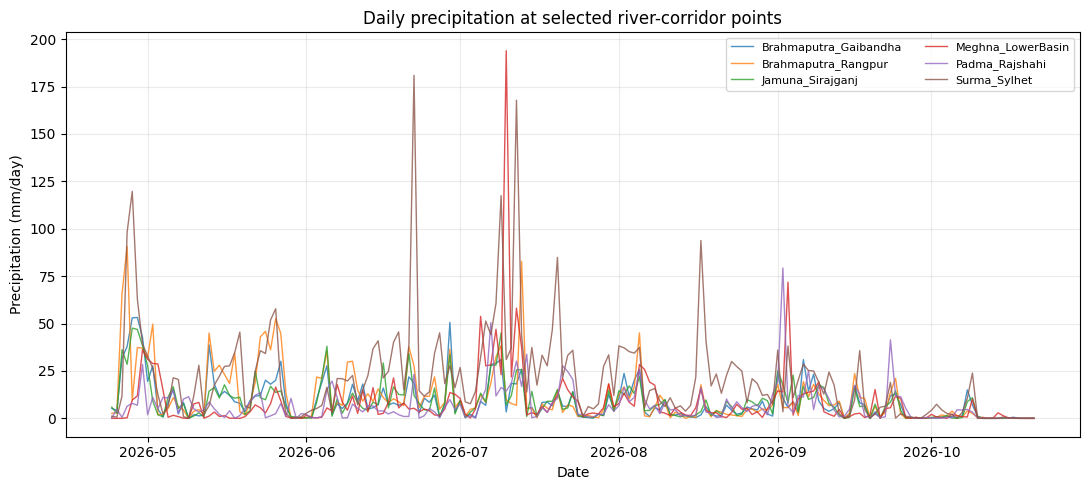

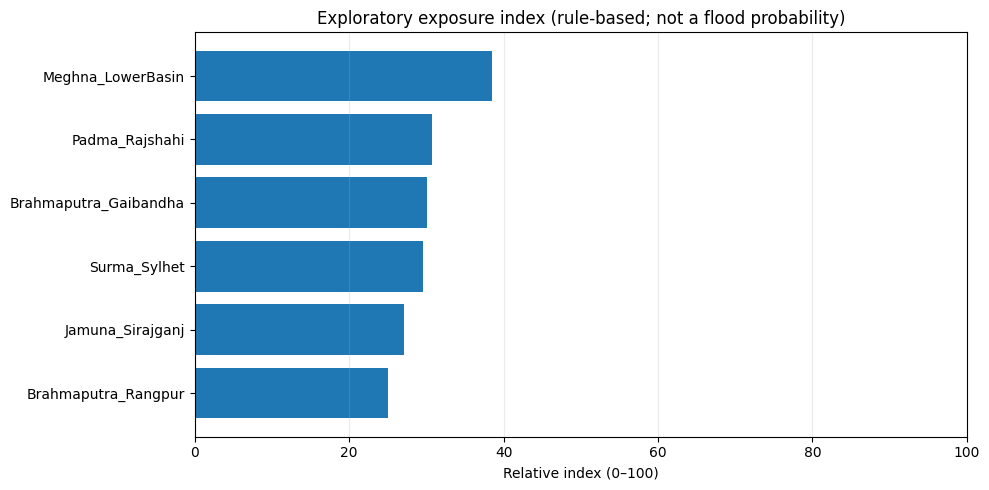

Saved 19,296 daily station rows to outputs/daily_weather_features.csv
Saved station summary to outputs/latest_exposure_summary.csv
Interpretation warning: the index is exploratory and has NOT been validated against flood observations.

Latest exploratory index (not a flood probability):


,station,river,latitude,longitude,latest_data_date,elevation_m_srtm,rainfall_latest_mm,rain_7d_sum_mm,rain_7d_historical_percentile,api_historical_percentile,low_elevation_indicator,exploratory_exposure_index_0_100
5,Meghna_LowerBasin,Meghna,23.200,90.700,2026-10-21,8.0,0.0,1.9,0.337376,0.330224,0.670320,38.517176
4,Padma_Rajshahi,Padma,24.363,88.601,2026-10-21,25.0,0.0,0.6,0.297575,0.335821,0.286505,30.738803
1,Brahmaputra_Gaibandha,Brahmaputra,25.328,89.528,2026-10-21,25.0,0.0,0.7,0.289801,0.327114,0.286505,30.050060
3,Surma_Sylhet,Surma,25.069,91.399,2026-10-21,15.0,0.0,0.9,0.244092,0.301617,0.472367,29.559068
2,Jamuna_Sirajganj,Jamuna,24.937,89.937,2026-10-21,25.0,0.0,0.3,0.240983,0.316853,0.286505,27.057211
0,Brahmaputra_Rangpur,Brahmaputra,25.807,89.636,2026-10-21,34.0,0.0,0.4,0.254664,0.276741,0.182684,25.049022



Short-range weather forecast indicators (not a flood forecast):


,station,river_or_area,latitude,longitude,forecast_fetched_at_local,forecast_start_local,rain_forecast_next_6h_mm,rain_forecast_next_24h_mm,rain_forecast_next_72h_mm,max_hourly_rain_next_24h_mm,max_precip_probability_next_24h_pct
3,Surma_Sylhet,Surma,25.0690,91.3990,2026-10-28T09:04:13.428331+06:00,2026-10-28 09:00:00,0.0,6.5,7.5,3.2,71.0
0,Brahmaputra_Rangpur,Brahmaputra,25.8070,89.6360,2026-10-28T09:04:10.170138+06:00,2026-10-28 09:00:00,0.0,6.3,11.3,4.1,55.0
1,Brahmaputra_Gaibandha,Brahmaputra,25.3280,89.5280,2026-10-28T09:04:11.581463+06:00,2026-10-28 09:00:00,0.0,6.0,15.7,3.9,54.0
4,Padma_Rajshahi,Padma,24.3630,88.6010,2026-10-28T09:04:14.353829+06:00,2026-10-28 09:00:00,0.0,5.9,18.5,4.6,31.0
6,Meghalaya_Cherrapunji_context,Meghalaya regional rainfall context,25.2700,91.7320,2026-10-28T09:04:16.200264+06:00,2026-10-28 09:00:00,2.9,4.5,16.3,1.0,61.0
7,Meghalaya_Shillong_context,Meghalaya regional rainfall context,25.5788,91.8933,2026-10-28T09:04:16.656343+06:00,2026-10-28 09:00:00,2.3,3.3,18.4,2.2,96.0
5,Meghna_LowerBasin,Meghna,23.2000,90.7000,2026-10-28T09:04:15.277728+06:00,2026-10-28 09:00:00,0.0,0.5,5.3,0.5,34.0
2,Jamuna_Sirajganj,Jamuna,24.9370,89.9370,2026-10-28T09:04:12.503411+06:00,2026-10-28 09:00:00,0.0,0.2,9.6,0.1,51.0
8,Tripura_Agartala_context,Tripura regional rainfall context,23.8315,91.2868,2026-10-28T09:04:17.114896+06:00,2026-10-28 09:00:00,0.0,0.0,1.3,0.0,35.0



Modelled GloFAS daily discharge (not observed gauge data):


,date,river_discharge_m3s_modelled,discharge_p25_m3s_modelled,discharge_p75_m3s_modelled,station,river_or_area,requested_latitude,requested_longitude,model_grid_latitude,model_grid_longitude,forecast_fetched_at_local
0,2026-10-28,85.30,85.30,85.30,Brahmaputra_Rangpur,Brahmaputra,25.807,89.636,25.825005,89.625000,2026-10-28T09:04:11.125045+06:00
1,2026-10-29,80.28,80.28,80.28,Brahmaputra_Rangpur,Brahmaputra,25.807,89.636,25.825005,89.625000,2026-10-28T09:04:11.125045+06:00
2,2026-10-30,75.56,75.56,75.74,Brahmaputra_Rangpur,Brahmaputra,25.807,89.636,25.825005,89.625000,2026-10-28T09:04:11.125045+06:00
3,2026-10-31,71.78,71.44,72.11,Brahmaputra_Rangpur,Brahmaputra,25.807,89.636,25.825005,89.625000,2026-10-28T09:04:11.125045+06:00
4,2026-11-01,69.96,68.34,71.69,Brahmaputra_Rangpur,Brahmaputra,25.807,89.636,25.825005,89.625000,2026-10-28T09:04:11.125045+06:00
5,2026-11-02,70.45,65.91,85.97,Brahmaputra_Rangpur,Brahmaputra,25.807,89.636,25.825005,89.625000,2026-10-28T09:04:11.125045+06:00
6,2026-11-03,73.13,64.31,144.05,Brahmaputra_Rangpur,Brahmaputra,25.807,89.636,25.825005,89.625000,2026-10-28T09:04:11.125045+06:00
7,2026-10-28,5.68,5.68,5.68,Brahmaputra_Gaibandha,Brahmaputra,25.328,89.528,25.325005,89.525024,2026-10-28T09:04:12.048335+06:00
8,2026-10-29,5.56,5.56,5.56,Brahmaputra_Gaibandha,Brahmaputra,25.328,89.528,25.325005,89.525024,2026-10-28T09:04:12.048335+06:00
9,2026-10-30,5.47,5.47,5.61,Brahmaputra_Gaibandha,Brahmaputra,25.328,89.528,25.325005,89.525024,2026-10-28T09:04:12.048335+06:00


In [6]:
# Run the complete prototype. First-time historical downloads may take a little while.
# If a live API is temporarily unavailable, the notebook records a warning and continues.
features, summary = run(include_live_forecasts=True)

print("\nLatest exploratory index (not a flood probability):")
display(summary.head(10))

summary_path = OUTPUT_DIR / "rainfall_forecast_summary.csv"
if summary_path.exists():
    print("\nShort-range weather forecast indicators (not a flood forecast):")
    display(pd.read_csv(summary_path).sort_values("rain_forecast_next_24h_mm", ascending=False).head(10))

discharge_path = OUTPUT_DIR / "glofas_discharge_forecast.csv"
if discharge_path.exists():
    print("\nModelled GloFAS daily discharge (not observed gauge data):")
    display(pd.read_csv(discharge_path).head(10))
